# Futures Spread Seasonality — Spaghetti Charts

Seasonal overlay ("spaghetti") charts of calendar spreads for grains and oilseeds, built from Barchart daily history.

* **`data_loader.py`** — loads the file(s), parses `Symbol` → `Root` / `Month` / `ContractYear`, drops non-contract series and duplicate rows.
* **`spread_engine.py`** — spread definitions, `build_spread()` (inner join on `Date`, `Spread = Leg1 − Leg2`), seasonal alignment and averages.
* **`plotter.py`** — interactive Plotly spaghetti charts (Matplotlib fallback).

**Alignment.** `CropYear` is the Leg 1 contract year. Every date is measured as `DaysToExpiry` = calendar days to the 1st of Leg 1's delivery month, then replotted on one reference calendar (`SeasonalDate`), so all years line up on a common month axis. The most recent crop year is drawn in bold red, history in grey (older = lighter), with the prior-5-year average (dashed) and min–max band.

In [1]:
import sys
from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\ahmed\OneDrive\Desktop\Python\Chart_Spreads")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import pandas as pd
import plotly.io as pio
import ipywidgets as widgets
from IPython.display import display

from data_loader import load_futures, available_roots, COMMODITIES
from spread_engine import (build_spread, build_named_spread, spreads_for_root,
                           available_spreads, seasonal_stats)
from plotter import plot_spaghetti, plot_spaghetti_mpl

pd.set_option("display.width", 160)

## 1. Load data

Barchart roots differ from the project's canonical codes (`KE` → `KW`, `ZW` → `W`, `ZC` → `C`); both spellings work everywhere. The path may be a file, a folder of `.csv` / `.xlsx` files, or a file name without its extension.

In [2]:
DATA_PATH = Path(r"C:\Users\ahmed\Downloads\Other Python\MW_KW_W_C")

df = load_futures(DATA_PATH)
roots = available_roots(df)
roots

Loaded 271,763 rows from MW_KW_W_C.csv
  dropped: 0 missing/zero Close, 5,303 duplicate Symbol/Date rows
  skipped non-contract symbols: ZLY00, ZMY00, ZSY00, ^CADUSD


,Name,Group,BarchartRoot,Months,FirstYear,LastYear,Contracts,Rows,FirstDate,LastDate
Root,,,,,,,,,,
C,Corn (CBOT),Grains,ZC,HKNUZ,2001,2023,114,33906,2000-03-07,2023-05-04
KW,HRW Wheat (KC),Grains,KE,HKNUZ,2001,2023,115,33049,2000-01-21,2023-05-04
W,SRW Wheat (CBOT),Grains,ZW,HKNUZ,2001,2023,114,33495,2000-03-22,2023-05-04
MW,Spring Wheat (MGEX/MIAX),Grains,MW,HKNUZ,2001,2023,115,31843,2000-01-12,2023-05-04
ZM,Soybean Meal (CBOT),Oilseed Products,ZM,Z,2001,2022,22,6600,2000-10-05,2022-12-14
ZL,Soybean Oil (CBOT),Oilseed Products,ZL,FHKNQUVZ,2001,2022,176,52776,1999-12-09,2022-12-14
RS,Canola (ICE),Oilseeds,RS,FHKNX,2001,2023,115,34018,2000-01-21,2023-08-28
ZS,Soybeans (CBOT),Oilseeds,ZS,FHKNQUX,2001,2022,154,46076,2000-01-05,2022-11-14


## 2. Spread definitions per root

Grains use `Z-H`, `H-K`, `K-N`, `N-Z`; canola and soybeans use `H-K`, `K-N`, `N-X`, `X-H`. Soy oil / meal have no November contract, so they use the Dec-anchored grain cycle. A pair only appears below if both legs exist in the data.

In [3]:
rows = []
for r in roots.index:
    for pair, (m1, m2, off) in spreads_for_root(r).items():
        rows.append({"Root": r, "Pair": pair, "Leg1": m1, "Leg2": m2,
                     "Leg2 year offset": off, "In data": pair in available_spreads(df, r)})
spread_defs = pd.DataFrame(rows)
spread_defs.pivot(index="Root", columns="Pair", values="In data").map(lambda v: {True: "yes", False: "no"}.get(v, ""))

Pair,H-K,K-N,N-X,N-Z,X-H,Z-H
Root,,,,,,
C,yes,yes,,yes,,yes
KW,yes,yes,,yes,,yes
MW,yes,yes,,yes,,yes
RS,yes,yes,yes,,yes,
W,yes,yes,,yes,,yes
ZL,yes,yes,,yes,,yes
ZM,no,no,,no,,no
ZS,yes,yes,yes,,yes,


## 3. Spring Wheat (MW) — Dec/Mar (`MWZ-MWH`)

In [4]:
mw_zh = build_spread(df, "MW", "Z", "H", year_offset=1, start_year=2010, end_year=2026)
mw_zh.tail()

,Date,CropYear,Leg1Symbol,Leg2Symbol,Leg1Close,Leg2Close,Spread,DaysToExpiry,DayOfYear,SeasonalDate,Label
3009,2022-11-22,2022,MWZ22,MWH23,946.0,950.3,-4.3,9,326,2000-11-22,MWZ-MWH (Dec/Mar)
3010,2022-11-23,2022,MWZ22,MWH23,957.8,952.3,5.5,8,327,2000-11-23,MWZ-MWH (Dec/Mar)
3011,2022-11-25,2022,MWZ22,MWH23,957.3,949.5,7.8,6,329,2000-11-25,MWZ-MWH (Dec/Mar)
3012,2022-11-28,2022,MWZ22,MWH23,951.3,939.8,11.5,3,332,2000-11-28,MWZ-MWH (Dec/Mar)
3013,2022-11-29,2022,MWZ22,MWH23,940.3,934.5,5.8,2,333,2000-11-29,MWZ-MWH (Dec/Mar)


In [5]:
plot_spaghetti(mw_zh, units="¢/bu").show()

## 4. Spring Wheat (MW) — Mar/May (`MWH-MWK`)

In [6]:
mw_hk = build_named_spread(df, "MW", "H-K")
plot_spaghetti(mw_hk, units="¢/bu").show()

## 5. Corn (C) — Jul/Dec (`CN-CZ`)

The old-crop / new-crop spread. Shown on the `DaysToExpiry` axis (counting down to July delivery) as an alternative to the calendar axis.

In [7]:
c_nz = build_named_spread(df, "C", "N-Z")
plot_spaghetti(c_nz, units="¢/bu", x_axis="DaysToExpiry").show()

## 6. Canola (RS) — Nov/Mar (`RSX-RSH`)

In [8]:
rs_xh = build_named_spread(df, "RS", "X-H")
plot_spaghetti(rs_xh, units="CAD/t").show()

### Where each year finished vs. the historical average

Last observed spread per crop year (the final days before Leg 1's delivery month).

In [9]:
def year_summary(s):
    last = s.sort_values("Date").groupby("CropYear").tail(1).set_index("CropYear")
    g = s.groupby("CropYear")["Spread"]
    return pd.DataFrame({"Last date": last["Date"].dt.date, "Last": last["Spread"],
                         "Min": g.min(), "Max": g.max(), "Mean": g.mean().round(2)})

year_summary(rs_xh)

,Last date,Last,Min,Max,Mean
CropYear,,,,,
2010,2010-11-12,-11.4,-17.3,4.0,-6.26
2011,2011-11-14,-9.1,-20.2,-4.5,-11.70
2012,2012-11-14,4.2,-12.4,11.3,-4.78
2013,2013-11-14,-15.6,-19.6,8.5,-4.12
2014,2014-11-14,11.4,-15.6,19.6,-8.41
2015,2015-11-13,-12.8,-16.8,9.1,-2.82
2016,2016-11-14,-13.5,-15.0,-1.4,-8.20
2017,2017-11-14,-9.7,-15.8,-1.8,-8.97
2018,2018-11-14,-14.5,-17.9,-3.7,-9.24


## 7. Matplotlib fallback (static)

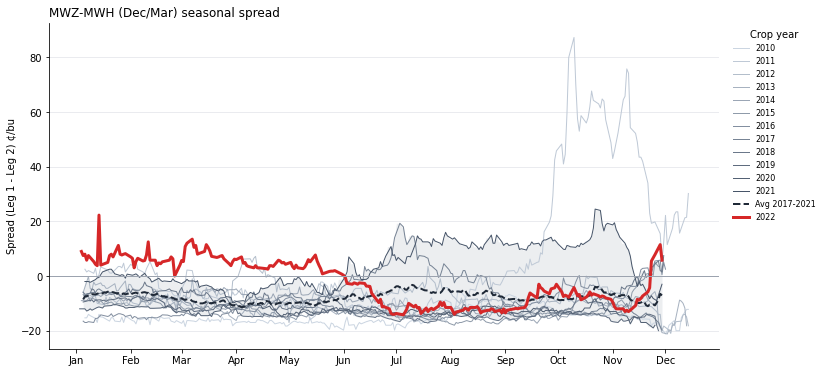

In [10]:
import matplotlib.pyplot as plt
plot_spaghetti_mpl(mw_zh, units="¢/bu")
plt.show()

## 8. Interactive explorer

Pick any commodity root and spread pair; the chart re-renders on every change. *Highlight* chooses the bold year, *Axis* switches between the calendar axis and days-to-delivery.

In [11]:
root_dd = widgets.Dropdown(
    options=[(f"{r} — {COMMODITIES.get(r, {}).get('name', r)}", r)
             for r in roots.index if available_spreads(df, r)],
    description="Commodity", layout=widgets.Layout(width="320px"))
pair_dd = widgets.Dropdown(description="Spread", layout=widgets.Layout(width="200px"))
years_sl = widgets.IntRangeSlider(value=(2010, 2026), min=2001, max=2026, description="Crop years",
                                  layout=widgets.Layout(width="380px"))
hi_dd = widgets.Dropdown(description="Highlight", layout=widgets.Layout(width="180px"))
axis_tb = widgets.ToggleButtons(options=[("Calendar", "SeasonalDate"), ("Days to delivery", "DaysToExpiry")],
                                description="Axis")
avg_cb = widgets.Checkbox(value=True, description="5-yr average & band")
out = widgets.Output()

_busy = False  # suppress re-renders while one control updates another

def _pairs(*_):
    opts = available_spreads(df, root_dd.value)
    pair_dd.options = opts
    pair_dd.value = opts[0] if opts else None

def _current():
    m1, m2, off = spreads_for_root(root_dd.value)[pair_dd.value]
    lo, hi = years_sl.value
    return build_spread(df, root_dd.value, m1, m2, off, start_year=lo, end_year=hi)

def _years(*_):
    yrs = [] if pair_dd.value is None else sorted(_current()["CropYear"].unique(), reverse=True)
    hi_dd.options = [int(y) for y in yrs]
    hi_dd.value = int(yrs[0]) if yrs else None

def _render(*_):
    if _busy:
        return
    out.clear_output(wait=True)
    with out:
        if pair_dd.value is None:
            print("No spread available.")
            return
        s = _current()
        if s.empty:
            print("No overlapping data for this pair / year range.")
            return
        plot_spaghetti(s, highlight_year=hi_dd.value, x_axis=axis_tb.value,
                       show_average=avg_cb.value, show_band=avg_cb.value).show()

def _on_change(change):
    global _busy
    _busy = True
    try:
        if change["owner"] is root_dd:
            _pairs()
        if change["owner"] in (root_dd, pair_dd, years_sl):
            _years()
    finally:
        _busy = False
    _render()

for w in (root_dd, pair_dd, years_sl, hi_dd, axis_tb, avg_cb):
    w.observe(_on_change, "value")

_busy = True
_pairs(); _years()
_busy = False
_render()
display(widgets.VBox([widgets.HBox([root_dd, pair_dd, hi_dd]),
                      widgets.HBox([years_sl, avg_cb]), axis_tb, out]))

## Notes

* The source file holds Barchart's ~300-row cap per contract (roughly the last 14 months of each contract), so each crop year covers about one year before Leg 1's delivery month.
* History in this file ends in 2023 (grains in May 2023, canola in Aug 2023). The highlighted "latest" year is the newest crop year with data — refresh the file to see 2024+.
* `ZM` (soybean meal) only carries December contracts, so no calendar spread can be built for it.